# Stage 2 – Task 3: Regression

### Mục tiêu
- Xây dựng mô hình dự đoán giá sản phẩm (`Price`).
- So sánh Linear Regression và Decision Tree Regressor.
- Đánh giá mô hình bằng MSE, RMSE và R².
- Trực quan hóa kết quả dự đoán.
- Lựa chọn và lưu mô hình tốt nhất dưới dạng file `.pkl` để tích hợp vào ứng dụng Streamlit.

### Quy trình thực hiện

1. Kiểm tra và chuẩn bị dữ liệu.
2. Xác định biến mục tiêu và các đặc trưng đầu vào.
3. Chia dữ liệu thành tập huấn luyện và tập kiểm tra.
4. Tiền xử lý dữ liệu số và dữ liệu phân loại.
5. Huấn luyện Linear Regression và Decision Tree Regressor.
6. Đánh giá, so sánh hiệu suất hai mô hình.
7. Trực quan hóa giá trị thực tế và giá trị dự đoán.
8. Lựa chọn mô hình tốt nhất và xuất file `.pkl`.

In [14]:
# Import thư viện xử lý dữ liệu
import os
import numpy as np
import pandas as pd

# Import thư viện trực quan hóa
import matplotlib.pyplot as plt

# Import các công cụ tiền xử lý
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Import các mô hình hồi quy
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Import các chỉ số đánh giá
from sklearn.metrics import mean_squared_error, r2_score

# Import công cụ lưu mô hình
import joblib

# Cố định seed để kết quả có thể tái lập
RANDOM_STATE = 42


### 1. Đọc và kiểm tra dữ liệu

Sử dụng bộ dữ liệu đã được xử lý ở Stage 1 của dự án.

Kiểm tra kích thước dữ liệu, tên cột, kiểu dữ liệu và các giá trị thiếu trước khi xây dựng mô hình hồi quy.

In [15]:
# Đường dẫn dữ liệu
DATA_PATH = "NguyenTheHoang_final_eda.csv"

# Tìm dữ liệu trong thư mục hiện tại hoặc thư mục data
if not os.path.exists(DATA_PATH):
    alternative_path = os.path.join("data", "NguyenTheHoang_final_eda.csv")

    if os.path.exists(alternative_path):
        DATA_PATH = alternative_path
    else:
        raise FileNotFoundError(
            "Không tìm thấy file dữ liệu. "
            "Hãy kiểm tra lại đường dẫn DATA_PATH."
        )

# Đọc dữ liệu
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Đọc dữ liệu thành công!")
print(f"Kích thước dữ liệu: {df.shape}")

display(df.head())

Đọc dữ liệu thành công!
Kích thước dữ liệu: (158656, 14)


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source,Sales Amount,Month,Weekday,Price Range,Source_Cafe Sales,Source_Coffee Shop Sales,Sales Amount (scaled)
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales,4.0,9,Friday,Low,True,False,-0.211372
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales,12.0,5,Tuesday,Medium,True,False,1.583948
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales,4.0,7,Wednesday,Low,True,False,-0.211372
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,Takeaway,Cafe Sales,10.0,4,Thursday,Medium,True,False,1.135118
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales,4.0,6,Sunday,Low,True,False,-0.211372


In [16]:
# Kiểm tra tên cột
print("Danh sách cột:")
print(df.columns.tolist())

# Kiểm tra kiểu dữ liệu
print("\nThông tin dữ liệu:")
df.info()

# Kiểm tra số lượng giá trị thiếu
print("\nSố lượng giá trị thiếu:")
display(df.isnull().sum().sort_values(ascending=False))

# Kiểm tra thống kê mô tả
print("\nThống kê mô tả:")
display(df.describe(include="all").T)

Danh sách cột:
['Transaction ID', 'Transaction Date', 'Product Name', 'Quantity', 'Price', 'Store Location', 'Source', 'Sales Amount', 'Month', 'Weekday', 'Price Range', 'Source_Cafe Sales', 'Source_Coffee Shop Sales', 'Sales Amount (scaled)']

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158656 entries, 0 to 158655
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Transaction ID            158656 non-null  object 
 1   Transaction Date          158656 non-null  object 
 2   Product Name              158656 non-null  object 
 3   Quantity                  158656 non-null  float64
 4   Price                     158656 non-null  float64
 5   Store Location            158656 non-null  object 
 6   Source                    158656 non-null  object 
 7   Sales Amount              158656 non-null  float64
 8   Month                     158656 non-null  int64  
 9   Week

Transaction ID              0
Transaction Date            0
Product Name                0
Quantity                    0
Price                       0
Store Location              0
Source                      0
Sales Amount                0
Month                       0
Weekday                     0
Price Range                 0
Source_Cafe Sales           0
Source_Coffee Shop Sales    0
Sales Amount (scaled)       0
dtype: int64


Thống kê mô tả:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,158656,158656,TXN_1961373,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,158656,365,2023-06-16,1371,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,158656,88,Chocolate Croissant,3076,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,158656.0,NaN,NaN,NaN,1.533633,0.730713,1.0,1.0,1.0,2.0,8.0
Price,158656.0,NaN,NaN,NaN,3.356391,2.597527,0.8,2.5,3.0,3.75,45.0
Store Location,158656,5,Hell's Kitchen,50735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,158656,2,Coffee Shop Sales,149116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Amount,158656.0,NaN,NaN,NaN,4.941879,4.456045,0.8,3.0,4.0,6.0,360.0
Month,158656.0,NaN,NaN,NaN,4.141318,1.926012,1.0,3.0,4.0,6.0,12.0
Weekday,158656,7,Friday,23089,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Xác định đặc trưng đầu vào và biến mục tiêu

Chọn `Price` làm biến mục tiêu cần dự đoán.

Các đặc trưng đầu vào gồm:
- `Quantity`: Số lượng sản phẩm.
- `Product Name`: Tên sản phẩm.
- `Store Location`: Địa điểm giao dịch.
- `Source`: Nguồn dữ liệu.
- `Month`: Tháng giao dịch.
- `Weekday`: Ngày trong tuần.

Không sử dụng các cột `Sales Amount`, `Sales Amount (scaled)` và `Price Range` làm đầu vào vì chúng có thể chứa thông tin được tính trực tiếp hoặc gián tiếp từ `Price`.

Cột `Transaction ID` cũng không được sử dụng vì đây là mã định danh giao dịch, không phải đặc trưng có ý nghĩa dự đoán trực tiếp.

Việc loại bỏ các cột này giúp hạn chế rò rỉ dữ liệu (data leakage).

In [17]:
# Xác định biến mục tiêu
TARGET = "Price"

# Danh sách đặc trưng đầu vào
FEATURES = [
    "Quantity",
    "Product Name",
    "Store Location",
    "Source",
    "Month",
    "Weekday"
]

# Kiểm tra các cột cần thiết
required_columns = FEATURES + [TARGET]
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

# Tạo dữ liệu đầu vào và biến mục tiêu
X = df[FEATURES].copy()
y = pd.to_numeric(df[TARGET], errors="coerce")

# Loại bỏ những dòng không có target hợp lệ
valid_rows = y.notna() & np.isfinite(y)

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Loại bỏ những dòng có giá không hợp lệ
valid_price = y >= 0

X = X.loc[valid_price].copy()
y = y.loc[valid_price].copy()

print("Số dòng dữ liệu hợp lệ:", len(X))
print("Số đặc trưng đầu vào:", X.shape[1])

print("\nCác đặc trưng:")
print(X.columns.tolist())

print("\nPhân bố giá:")
display(y.describe())

Số dòng dữ liệu hợp lệ: 158656
Số đặc trưng đầu vào: 6

Các đặc trưng:
['Quantity', 'Product Name', 'Store Location', 'Source', 'Month', 'Weekday']

Phân bố giá:


count    158656.000000
mean          3.356391
std           2.597527
min           0.800000
25%           2.500000
50%           3.000000
75%           3.750000
max          45.000000
Name: Price, dtype: float64

### 3. Chia dữ liệu thành tập huấn luyện và tập kiểm tra

Sử dụng `train_test_split` để chia dữ liệu theo tỷ lệ:
- 80% dữ liệu huấn luyện.
- 20% dữ liệu kiểm tra.

Thiết lập `random_state=42` để đảm bảo kết quả có thể tái lập.

Tập kiểm tra chỉ được sử dụng để đánh giá hiệu suất của mô hình trên những quan sát chưa được sử dụng trong quá trình huấn luyện.

In [18]:
# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Kích thước tập huấn luyện:", X_train.shape)
print("Kích thước tập kiểm tra:", X_test.shape)

print("\nSố dòng y_train:", len(y_train))
print("Số dòng y_test:", len(y_test))

Kích thước tập huấn luyện: (126924, 6)
Kích thước tập kiểm tra: (31732, 6)

Số dòng y_train: 126924
Số dòng y_test: 31732


### 4. Tiền xử lý dữ liệu

Các mô hình hồi quy cần dữ liệu đầu vào ở dạng số.

Quy trình tiền xử lý gồm:

**Đối với dữ liệu số:**
- Thay thế giá trị thiếu bằng median.
- Chuẩn hóa dữ liệu bằng `StandardScaler`.

**Đối với dữ liệu phân loại:**
- Thay thế giá trị thiếu bằng giá trị xuất hiện nhiều nhất.
- Sử dụng `OneHotEncoder` để chuyển đổi dữ liệu phân loại thành dạng số.

Sử dụng `ColumnTransformer` và `Pipeline` để kết hợp tiền xử lý với mô hình.

Các bộ tiền xử lý chỉ được fit trên tập huấn luyện nhằm hạn chế rò rỉ dữ liệu từ tập kiểm tra.

In [19]:
# Xác định nhóm đặc trưng số và phân loại
NUMERIC_FEATURES = [
    "Quantity",
    "Month"
]

CATEGORICAL_FEATURES = [
    "Product Name",
    "Store Location",
    "Source",
    "Weekday"
]

# Pipeline xử lý dữ liệu số
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Pipeline xử lý dữ liệu phân loại
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Kết hợp các bước tiền xử lý
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            categorical_transformer,
            CATEGORICAL_FEATURES
        )
    ]
)

print("Đã xây dựng bộ tiền xử lý dữ liệu.")

Đã xây dựng bộ tiền xử lý dữ liệu.


### 5. Xây dựng và huấn luyện hai mô hình hồi quy

Hai thuật toán được sử dụng:

**Linear Regression**

Mô hình tuyến tính, giả định mối quan hệ giữa các đặc trưng và biến mục tiêu có thể được biểu diễn bằng một tổ hợp tuyến tính.

**Decision Tree Regressor**

Mô hình cây quyết định, phân chia dữ liệu thành các vùng dựa trên đặc trưng đầu vào và dự đoán giá trị trong từng vùng.

Hai mô hình sử dụng cùng tập huấn luyện, tập kiểm tra và quy trình tiền xử lý để đảm bảo việc so sánh công bằng.

In [20]:
# Khởi tạo hai mô hình
models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(random_state=42))
    ])
}

# Huấn luyện các mô hình
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Đã huấn luyện xong: {name}")

Đã huấn luyện xong: Linear Regression
Đã huấn luyện xong: Decision Tree


### 6. Đánh giá hiệu suất mô hình

Sử dụng ba chỉ số để đánh giá:

- **MSE (Mean Squared Error):** Sai số bình phương trung bình giữa giá trị thực tế và giá trị dự đoán. Giá trị càng thấp càng tốt.
- **RMSE (Root Mean Squared Error):** Căn bậc hai của MSE, có cùng đơn vị với biến mục tiêu `Price`. Giá trị càng thấp càng tốt.
- **R² (Coefficient of Determination):** Đo lường mức độ mô hình giải thích biến thiên của biến mục tiêu. Giá trị càng gần 1 càng tốt.

Mô hình tốt nhất sẽ được xác định dựa trên kết quả thực nghiệm trên tập kiểm tra.

In [21]:
# Dự đoán trên tập kiểm tra
y_pred_linear = linear_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)

# Hàm tính các chỉ số
def evaluate_regression(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

# Đánh giá hai mô hình
results = [
    evaluate_regression(
        y_test,
        y_pred_linear,
        "LinearRegression"
    ),
    evaluate_regression(
        y_test,
        y_pred_tree,
        "DecisionTreeRegressor"
    )
]

# Tạo bảng so sánh
results_df = pd.DataFrame(results)

## 7. So sánh kết quả hai mô hình

So sánh Linear Regression và Decision Tree Regression dựa trên các chỉ số:
- **MSE (Mean Squared Error):** Sai số bình phương trung bình, càng thấp càng tốt.
- **RMSE (Root Mean Squared Error):** Căn bậc hai của MSE, càng thấp càng tốt.
- **R² (R-squared):** Mức độ giải thích sự biến thiên của dữ liệu, càng gần 1 càng tốt.

In [22]:
# Hiển thị bảng so sánh kết quả
display(results_df)

,Model,MSE,RMSE,R2
0,LinearRegression,0.025861,0.160815,0.996264
1,DecisionTreeRegressor,0.035647,0.188803,0.994850


## 8. Trực quan hóa kết quả dự đoán

Vẽ biểu đồ Actual vs Predicted để so sánh giá trị thực tế với giá trị dự đoán của từng mô hình.

Các điểm càng gần đường chéo thì dự đoán càng sát với giá trị thực tế.

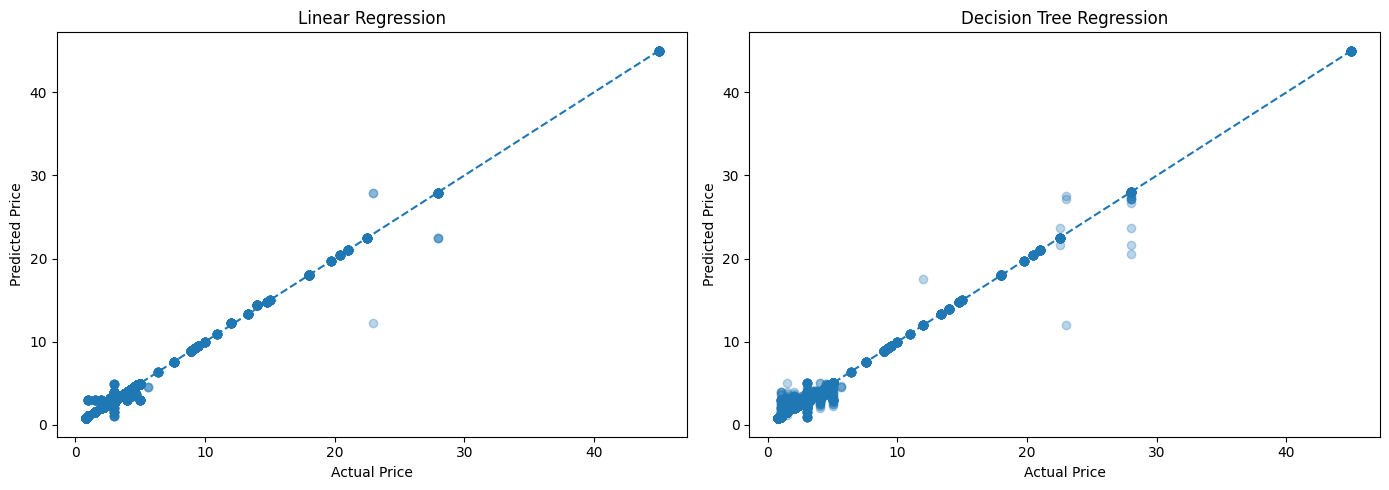

In [23]:
# Dự đoán trên tập kiểm tra
y_pred_lr = models["Linear Regression"].predict(X_test)
y_pred_dt = models["Decision Tree"].predict(X_test)

# Xác định phạm vi chung cho hai biểu đồ
y_min = min(y_test.min(), y_pred_lr.min(), y_pred_dt.min())
y_max = max(y_test.max(), y_pred_lr.max(), y_pred_dt.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear Regression
axes[0].scatter(y_test, y_pred_lr, alpha=0.3)
axes[0].plot(
    [y_min, y_max],
    [y_min, y_max],
    linestyle="--"
)
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

# Decision Tree Regression
axes[1].scatter(y_test, y_pred_dt, alpha=0.3)
axes[1].plot(
    [y_min, y_max],
    [y_min, y_max],
    linestyle="--"
)
axes[1].set_title("Decision Tree Regression")   
axes[1].set_xlabel("Actual Price")
axes[1].set_ylabel("Predicted Price")

plt.tight_layout()
plt.show()

## 9. Lựa chọn mô hình tốt nhất

Chọn mô hình có RMSE thấp nhất trên tập kiểm tra. RMSE càng thấp thì sai số dự đoán càng nhỏ.

In [25]:
# Chọn mô hình có RMSE thấp nhất
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

# Ánh xạ tên trong bảng kết quả với tên trong models
model_name_mapping = {
    "LinearRegression": "Linear Regression",
    "Linear Regression": "Linear Regression",
    "DecisionTreeRegressor": "Decision Tree",
    "Decision Tree": "Decision Tree"
}

model_key = model_name_mapping.get(
    best_model_name,
    best_model_name
)

best_model = models[model_key]

print("Mô hình được chọn:", best_model_name)

display(
    results_df[
        results_df["Model"] == best_model_name
    ]
)

Mô hình được chọn: LinearRegression


,Model,MSE,RMSE,R2
0,LinearRegression,0.025861,0.160815,0.996264


## 10. Lưu mô hình tốt nhất

Lưu mô hình được lựa chọn thành file pickle (`.pkl`) để sử dụng lại mà không cần huấn luyện lại từ đầu.

Theo yêu cầu, chỉ xuất file mô hình `.pkl`, không xuất thêm CSV hoặc hình ảnh.

In [26]:
import os
import joblib

# Đường dẫn lưu mô hình
MODEL_PATH = "data/LeGiaBao_regression_model.pkl"

# Tạo thư mục data nếu chưa tồn tại
os.makedirs("data", exist_ok=True)

# Lưu mô hình tốt nhất
joblib.dump(best_model, MODEL_PATH)

print("Mô hình đã được lưu tại:", MODEL_PATH)

Mô hình đã được lưu tại: data/LeGiaBao_regression_model.pkl


## 11. Kiểm tra mô hình đã lưu

Tải lại mô hình từ file `.pkl` và sử dụng để dự đoán một số mẫu trong tập kiểm tra, nhằm xác nhận mô hình có thể được sử dụng lại.

In [27]:
# Tải mô hình từ file pickle
loaded_model = joblib.load(MODEL_PATH)

# Dự đoán một số mẫu
sample_X = X_test.head(5)
sample_y = y_test.loc[sample_X.index]
sample_predictions = loaded_model.predict(sample_X)

# So sánh giá trị thực tế và giá trị dự đoán
comparison_df = pd.DataFrame({
    "Actual Price": sample_y.to_numpy(),
    "Predicted Price": sample_predictions
})

display(comparison_df)

,Actual Price,Predicted Price
0,3.00,3.000911
1,0.80,0.800928
2,3.50,3.503501
3,3.75,3.755151
4,3.00,2.998951


## 12. Kết luận

Đã xây dựng và so sánh hai mô hình hồi quy: Linear Regression và Decision Tree Regression.

Các mô hình được đánh giá bằng MSE, RMSE và R² trên tập kiểm tra. Mô hình có RMSE thấp nhất được lựa chọn và lưu dưới định dạng `.pkl` để sử dụng lại.

Biểu đồ Actual vs Predicted được sử dụng để quan sát mức độ phù hợp giữa giá trị thực tế và giá trị dự đoán.

Kết quả thực nghiệm được thể hiện trong bảng so sánh và biểu đồ ở phía trên.